<a href="https://colab.research.google.com/github/Martazzz/dropout_rate_academic_success/blob/main/02_block_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Block D: First-year performance

Phase 2 of the project (research blocks). Data: `student_dropout_cleaned.csv` (output of the cleaning phase).

**Goal of the block.** Show *when* the differences between students who drop out and students who graduate become visible, looking at the first two semesters.

**Important to remember.**
- Performance in the semesters is partly a **consequence** of dropping out (someone who is about to leave passes fewer exams), not only a cause. The block describes *when* the signs appear, not *why*.
- `Enrolled` is not a final outcome: these students have not finished yet.
- 180 students were enrolled in 0 units in each semester: they have no approval rate and are left out of the analyses that use it (the number of students `n` is always printed).

**Method for each question:** chart, statistical test, effect size and a one-sentence conclusion. With thousands of students almost every difference is "significant", so the conclusion is based on the size of the effect.

| Test | Used for | Effect size | Reading |
|---|---|---|---|
| Kruskal-Wallis | a numeric variable compared across the 3 outcomes | epsilon squared | < 0.01 negligible, 0.01-0.06 small, 0.06-0.14 medium, > 0.14 large |
| Chi-square | two categorical variables | Cramer's V | < 0.1 negligible, 0.1-0.3 weak, 0.3-0.5 moderate, > 0.5 strong |
| Spearman correlation | two numeric variables | rho | < 0.1 negligible, 0.1-0.3 weak, 0.3-0.5 moderate, > 0.5 strong |

## Setup: style and palette

This cell must be identical in all the notebooks of the group (same colors for the outcomes: orange = dropout, gray = enrolled, blue = graduate). The notebook expects `student_dropout_cleaned.csv` in the same folder.

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

OUTCOME_ORDER = ["Dropout", "Enrolled", "Graduate"]
OUTCOME_PALETTE = {"Dropout": "#9b4141", "Enrolled": "#b8b8b8", "Graduate": "#298c8c"}
BAR_COLOR = "#0072B2"
DROPOUT_COLOR = "#9b4141"

os.makedirs("figures", exist_ok=True)

ORDER = {
    "Target": OUTCOME_ORDER,
    "Gender": ["Female", "Male"],
    "Displaced": ["No", "Yes"],
    "Debtor": ["No", "Yes"],
    "Tuition_Up_To_Date": ["No", "Yes"],
    "Scholarship_Holder": ["No", "Yes"],
    "Daytime_Evening": ["Daytime", "Evening"],
    "Marital_Group": ["Single", "Not single"],
    "Age_Group": ["17-19", "20-24", "25-29", "30+"],
    "Admission_Grade_Band": ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    "Parent_Education": ["Basic", "Secondary", "Higher", "Unknown"],
    "Application_Order_Group": ["0-1", "2", "3+"],
    "Application_Mode_Group": [
        "General contingent",
        "Over 23 years old",
        "Transfer or change",
        "Prior diploma holder",
        "Special or other",
    ],
    "Passed_None_1st": ["No", "Yes"],
    "Passed_None_2nd": ["No", "Yes"],
}


def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

## Load the data and helper functions

The data are loaded with `apply_order`, which restores the order of the categories. The helper functions run the tests and print the results in a standard format.

In [ ]:
data = apply_order(pd.read_csv("student_dropout_cleaned.csv"))
data.shape

(4424, 41)

In [ ]:
def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


def format_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def chi2_test(df, col, target="Target"):
    table = pd.crosstab(df[col], df[target])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f"Chi-square test, {col} vs {target}: chi2 = {chi2:.1f}, dof = {dof}, {format_p(p)}, "
          f"Cramer's V = {cramers_v(table):.2f}")
    return table


def kruskal_test(df, col, target="Target"):
    groups = [df.loc[df[target] == o, col].dropna() for o in OUTCOME_ORDER]
    h, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    print(f"Kruskal-Wallis test, {col} by {target}: H = {h:.1f}, {format_p(p)}, "
          f"epsilon squared = {h / (n - 1):.2f}, n = {n}")


def spearman_test(df, x, y):
    sub = df[[x, y]].dropna()
    rho, p = stats.spearmanr(sub[x], sub[y])
    print(f"Spearman correlation, {x} vs {y}: rho = {rho:.2f}, {format_p(p)}, n = {len(sub)}")
    return rho


def outcome_summary(col):
    out = data.groupby("Target", observed=True)[col].agg(["count", "mean", "median"]).round(2)
    out.columns = ["n", "mean", "median"]
    print(col)
    print(out)
    print()


def dropout_rates(col):
    out = data.groupby(col, observed=True)["Dropout_Binary"].agg(["mean", "count"])
    out["mean"] = (out["mean"] * 100).round(1)
    out.columns = ["dropout_rate_%", "n"]
    return out


def plot_outcome_composition(ax, col):
    pct = pd.crosstab(data[col], data["Target"], normalize="index")[OUTCOME_ORDER] * 100
    n = data[col].value_counts()
    pct.plot(kind="barh", stacked=True, width=0.7, ax=ax,
             color=[OUTCOME_PALETTE[o] for o in OUTCOME_ORDER])
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
    ax.set_yticklabels([f"{c} (n={n[c]})" for c in pct.index], rotation=0)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage of students (%)")
    ax.set_ylabel("")
    ax.legend(title="Outcome", loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(axis="y", visible=False)

# D1. Approved units in the two semesters

**Question:** how many units do students who later drop out pass in each semester, compared with those who graduate?

**Variables:** `Approval_Rate_1st`, `Approval_Rate_2nd` (approved units / enrolled units) vs `Target`.

**Method:** grouped bar chart (semester x outcome) with the mean approval rate, and a Kruskal-Wallis test for each semester. The bars show the mean; the medians are printed in the tables.

Approval_Rate_1st
             n  mean  median
Target                      
Dropout   1344  0.41     0.4
Enrolled   766  0.71     0.8
Graduate  2134  0.93     1.0

Kruskal-Wallis test, Approval_Rate_1st by Target: H = 1941.1, p < 0.001, epsilon squared = 0.46, n = 4244
Approval_Rate_2nd
             n  mean  median
Target                      
Dropout   1344  0.31    0.17
Enrolled   766  0.67    0.71
Graduate  2134  0.93    1.00

Kruskal-Wallis test, Approval_Rate_2nd by Target: H = 2324.5, p < 0.001, epsilon squared = 0.55, n = 4244


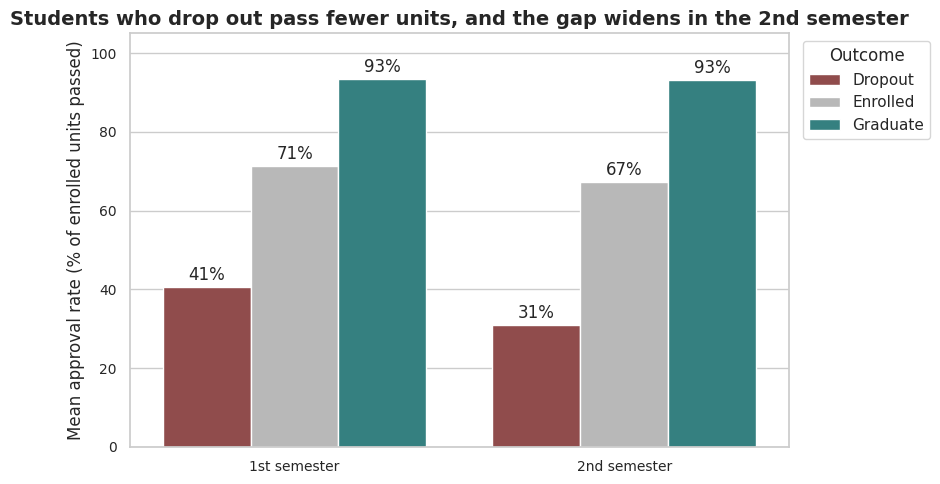

In [ ]:
for col in ["Approval_Rate_1st", "Approval_Rate_2nd"]:
    outcome_summary(col)
    kruskal_test(data, col)

long = data.melt(id_vars="Target", value_vars=["Approval_Rate_1st", "Approval_Rate_2nd"],
                 var_name="Semester", value_name="Approval_Rate")
long["Semester"] = long["Semester"].map({"Approval_Rate_1st": "1st semester",
                                         "Approval_Rate_2nd": "2nd semester"})
long["Approval_Rate"] = long["Approval_Rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=long, x="Semester", y="Approval_Rate", hue="Target", hue_order=OUTCOME_ORDER,
            palette=OUTCOME_PALETTE, errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=2)
ax.set_ylim(0, 105)
ax.set_xlabel("")
ax.set_ylabel("Mean approval rate (% of enrolled units passed)")
ax.set_title("Students who drop out pass fewer units, and the gap widens in the 2nd semester")
ax.legend(title="Outcome", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("figures/blockD_approval_rate_by_outcome.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion (check the numbers after running):** Students who drop out pass on average 41% of their enrolled units in the 1st semester and 31% in the 2nd, against 93% in both semesters for graduates (students still enrolled: 71% and 67%). The differences are statistically significant (Kruskal-Wallis, p < 0.001) and large (epsilon squared = 0.46 and 0.55). The gap widens in the 2nd semester because dropouts pass fewer units, while graduates stay stable.

# D2. Grades by outcome

**Question:** are the semester grades different by outcome?

**Variables:** `Grade_1st`, `Grade_2nd` vs `Target`.

**Method:** boxplots by outcome and a Kruskal-Wallis test for each semester.

**Caution:** the grade is the average of the *passed* units, so students who passed no unit have no grade (they are missing, not zero). The groups are therefore not complete: the table "Share of students with a grade" shows how many students of each outcome enter the comparison.

Grade_1st
             n   mean  median
Target                       
Dropout    851  12.12   12.00
Enrolled   723  12.22   12.12
Graduate  2132  13.10   13.02

Kruskal-Wallis test, Grade_1st by Target: H = 474.5, p < 0.001, epsilon squared = 0.13, n = 3706
Grade_2nd
             n   mean  median
Target                       
Dropout    694  12.08    12.0
Enrolled   726  12.16    12.0
Graduate  2134  13.14    13.0

Kruskal-Wallis test, Grade_2nd by Target: H = 497.9, p < 0.001, epsilon squared = 0.14, n = 3554
Share of students with a grade (% of each outcome)
          Grade_1st  Grade_2nd
Target                        
Dropout        60.0       49.0
Enrolled       91.0       91.0
Graduate       97.0       97.0


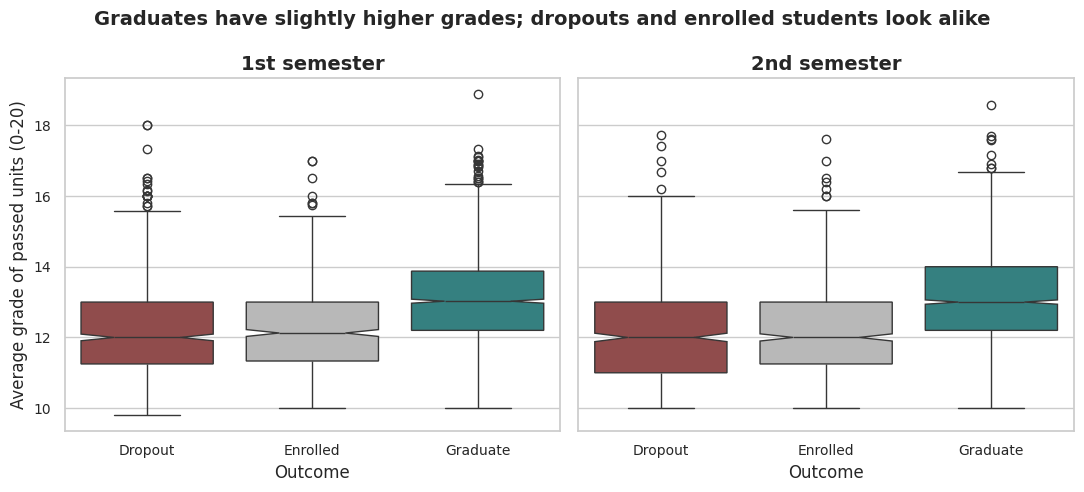

In [ ]:
for col in ["Grade_1st", "Grade_2nd"]:
    outcome_summary(col)
    kruskal_test(data, col)

share_with_grade = data.groupby("Target", observed=True)[["Grade_1st", "Grade_2nd"]].apply(
    lambda g: (g.notna().mean() * 100).round(0))
print("Share of students with a grade (% of each outcome)")
print(share_with_grade)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, col, title in zip(axes, ["Grade_1st", "Grade_2nd"], ["1st semester", "2nd semester"]):
    sns.boxplot(data=data, x="Target", y=col, hue="Target", notch=True, order=OUTCOME_ORDER,
                palette=OUTCOME_PALETTE, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Average grade of passed units (0-20)")
fig.suptitle("Graduates have slightly higher grades; dropouts and enrolled students look alike",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/blockD_grades_by_outcome.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion (check the numbers after running):** Among students who passed at least one unit, graduates have slightly higher grades (median 13.0 in both semesters) than dropouts (12.0) and students still enrolled (12.0-12.1). The differences are significant (p < 0.001) and medium in size (epsilon squared = 0.13 and 0.14), much smaller than the differences in approved units (D1). Many dropouts are not in the comparison (only 60% have a 1st semester grade and 49% a 2nd semester grade, against 97% of graduates), so grades alone describe a selected group.

# D3. Can dropouts be spotted after the 1st semester?

**Question:** can those who will drop out already be seen after the 1st semester?

**Variables:** `Approval_Rate_1st` (grouped into four bands) and `Passed_None_1st` vs `Dropout_Binary`.

**Method:** bar chart of the dropout rate by band of the approval rate, chi-square test with Cramer's V. The bands are created here and are not saved in the dataset. We also check how many of all the dropouts would be caught by a simple rule ("passed no unit" or "passed less than half").

Chi-square test, Approval_Band_1st vs Dropout_Binary: chi2 = 1565.6, dof = 3, p < 0.001, Cramer's V = 0.61
Chi-square test, Passed_None_1st vs Dropout_Binary: chi2 = 1020.7, dof = 1, p < 0.001, Cramer's V = 0.49
                   dropout_rate_%     n
Approval_Band_1st                      
None passed                  91.6   538
Under 50%                    72.9   310
50-99%                       28.4  1668
All passed                    8.7  1728
Dropouts: 1421
Passed no unit in the 1st semester: 493 (35% of all dropouts)
Approval rate under 50% in the 1st semester: 719 (51% of all dropouts)
Students without an approval rate (enrolled in 0 units): 180


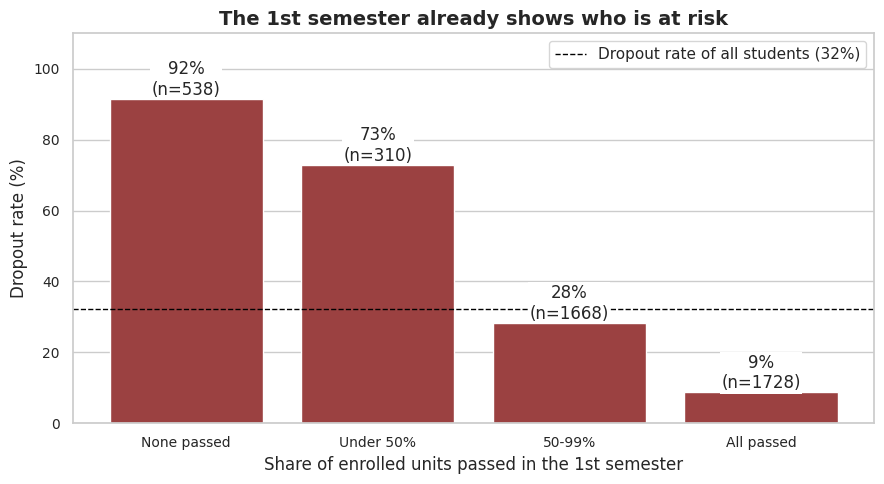

In [ ]:
rate = data["Approval_Rate_1st"]
band = pd.Series(np.select([rate == 0, rate < 0.5, rate < 1],
                           ["None passed", "Under 50%", "50-99%"], default="All passed"),
                 index=data.index).where(rate.notna())
data["Approval_Band_1st"] = pd.Categorical(
    band, categories=["None passed", "Under 50%", "50-99%", "All passed"], ordered=True)

table = chi2_test(data, "Approval_Band_1st", "Dropout_Binary")
table_none = chi2_test(data, "Passed_None_1st", "Dropout_Binary")
rates = dropout_rates("Approval_Band_1st")
print(rates)

dropouts = data[data["Dropout_Binary"] == 1]
n_dropouts = len(dropouts)
print(f"Dropouts: {n_dropouts}")
print(f"Passed no unit in the 1st semester: {(dropouts['Passed_None_1st'] == 'Yes').sum()} "
      f"({(dropouts['Passed_None_1st'] == 'Yes').mean() * 100:.0f}% of all dropouts)")
print(f"Approval rate under 50% in the 1st semester: {(dropouts['Approval_Rate_1st'] < 0.5).sum()} "
      f"({(dropouts['Approval_Rate_1st'] < 0.5).mean() * 100:.0f}% of all dropouts)")
print(f"Students without an approval rate (enrolled in 0 units): {data['Approval_Rate_1st'].isna().sum()}")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(rates.index.astype(str), rates["dropout_rate_%"], color=DROPOUT_COLOR)
ax.bar_label(bars, labels=[f"{r:.0f}%\n(n={n})" for r, n in zip(rates["dropout_rate_%"], rates["n"])],
             bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axhline(data["Dropout_Binary"].mean() * 100, color="black", linestyle="--", linewidth=1,
           label="Dropout rate of all students (32%)")
ax.legend(loc="upper right")
ax.set_ylim(0, 110)
ax.set_xlabel("Share of enrolled units passed in the 1st semester")
ax.set_ylabel("Dropout rate (%)")
ax.set_title("The 1st semester already shows who is at risk")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("figures/blockD_dropout_by_first_semester_approval.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion (check the numbers after running):** The dropout rate falls steeply with the share of units passed in the 1st semester: 92% for students who passed no unit (n = 538), 73% for those who passed less than half (n = 310), 28% for 50-99% and 9% for those who passed all (n = 1728). The association is strong (chi-square, p < 0.001, Cramer's V = 0.61). However, the signal is not enough alone: only 35% of the dropouts passed no unit and 51% passed less than half, so about half of the students who drop out look normal after the 1st semester. This supports using the 1st semester in the prediction model (Phase 4), but not as the only warning sign.

# D4. Do students who struggle in the 1st semester recover?

**Question:** do students who do badly in the 1st semester recover in the 2nd?

**Variables:** `Grade_Change` (2nd minus 1st semester grade) vs `Target`; approval rate of the 2nd semester for students who passed less than half of their units in the 1st.

**Method:** bar chart of the mean grade change by outcome (with 95% confidence interval) and Kruskal-Wallis test. Because `Grade_Change` exists only for students with a grade in both semesters (mostly students who were not doing badly), we also look directly at the students who passed less than half of their units in the 1st semester and check how many passed at least half in the 2nd.

Grade_Change
             n  mean  median
Target                      
Dropout    670 -0.08     0.0
Enrolled   710 -0.07     0.0
Graduate  2132  0.04     0.0

Kruskal-Wallis test, Grade_Change by Target: H = 16.5, p < 0.001, epsilon squared = 0.00, n = 3512


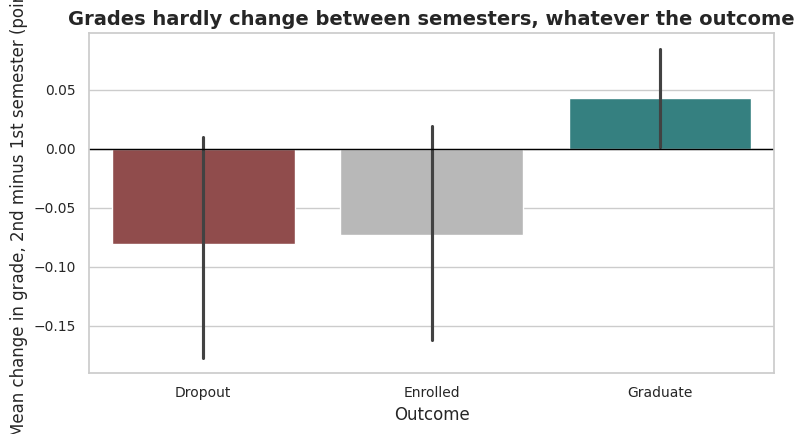

In [ ]:
outcome_summary("Grade_Change")
kruskal_test(data, "Grade_Change")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=data, x="Target", y="Grade_Change", hue="Target", order=OUTCOME_ORDER,
            palette=OUTCOME_PALETTE, errorbar=("ci", 95), legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Outcome")
ax.set_ylabel("Mean change in grade, 2nd minus 1st semester (points)")
ax.set_title("Grades hardly change between semesters, whatever the outcome")
plt.tight_layout()
plt.savefig("figures/blockD_grade_change_by_outcome.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion for the grade change:** Grades hardly change between the two semesters: the mean change is -0.08 points for dropouts, -0.07 for students still enrolled and +0.04 for graduates. The difference is statistically significant (Kruskal-Wallis, p < 0.001) but negligible in size (epsilon squared = 0.005), and the median change is 0 in all groups.

Students who passed less than half of their units in the 1st semester: 848
Of them, passed at least half in the 2nd semester: 86 (10%)

          sum  count  mean
Target                    
Dropout    30    719  0.04
Enrolled   49    121  0.40
Graduate    7      8  0.88

Chi-square test, First_Semester vs Target: chi2 = 1465.7, dof = 2, p < 0.001, Cramer's V = 0.59


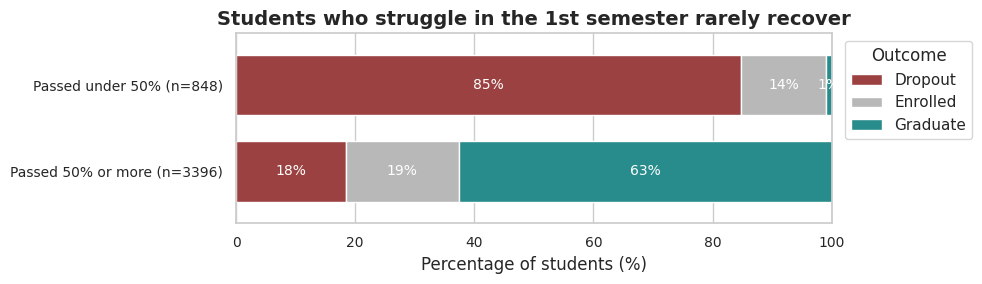

In [ ]:
struggling = data[data["Approval_Rate_1st"] < 0.5].dropna(subset=["Approval_Rate_2nd"]).copy()
struggling["Recovered_2nd"] = struggling["Approval_Rate_2nd"] >= 0.5
print(f"Students who passed less than half of their units in the 1st semester: {len(struggling)}")
print(f"Of them, passed at least half in the 2nd semester: {struggling['Recovered_2nd'].sum()} "
      f"({struggling['Recovered_2nd'].mean() * 100:.0f}%)")
print()
print(struggling.groupby("Target", observed=True)["Recovered_2nd"].agg(["sum", "count", "mean"]).round(2))
print()

compare = data.dropna(subset=["Approval_Rate_1st"]).copy()
compare["First_Semester"] = pd.Categorical(
    np.where(compare["Approval_Rate_1st"] < 0.5, "Passed under 50%", "Passed 50% or more"),
    categories=["Passed under 50%", "Passed 50% or more"], ordered=True)
table = chi2_test(compare, "First_Semester")

n_groups = compare["First_Semester"].value_counts()
pct = pd.crosstab(compare["First_Semester"], compare["Target"], normalize="index")[OUTCOME_ORDER] * 100
fig, ax = plt.subplots(figsize=(10, 3))
pct.plot(kind="barh", stacked=True, width=0.7, ax=ax, color=[OUTCOME_PALETTE[o] for o in OUTCOME_ORDER])
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
ax.set_yticklabels([f"{c} (n={n_groups[c]})" for c in pct.index], rotation=0)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of students (%)")
ax.set_ylabel("")
ax.legend(title="Outcome", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", visible=False)
ax.set_title("Students who struggle in the 1st semester rarely recover")
plt.tight_layout()
plt.savefig("figures/blockD_struggling_first_semester.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion for recovery (check the numbers after running):** Of the 848 students who passed less than half of their units in the 1st semester, only 10% (86) passed at least half in the 2nd, and 85% of them dropped out (against 18% among students who passed half or more). Recovery is rare, and mostly happens among the students still enrolled (40%), not among dropouts (4%). The association between a weak 1st semester and the outcome is strong (chi-square, p < 0.001, Cramer's V = 0.59). Graduates who struggled in the 1st semester are only 8 students: too few to draw conclusions.

# D5. Does the admission grade predict the 1st semester grade?

**Question:** does the admission grade predict the 1st semester grade?

**Variables:** `Admission_Grade` (0-200) vs `Grade_1st` (0-20), only for students with a 1st semester grade.

**Method:** scatter plot and Spearman correlation (the grade is not normally distributed). The median grade by quartile of the admission grade is printed as a second view. We also check the correlation with the approval rate.

Spearman correlation, Admission_Grade vs Grade_1st: rho = 0.29, p < 0.001, n = 3706
Spearman correlation, Admission_Grade vs Approval_Rate_1st: rho = 0.17, p < 0.001, n = 4244
                      count  median
Admission_Grade_Band               
Q1 (lowest)             902   12.12
Q2                      952   12.42
Q3                      948   12.80
Q4 (highest)            904   13.25


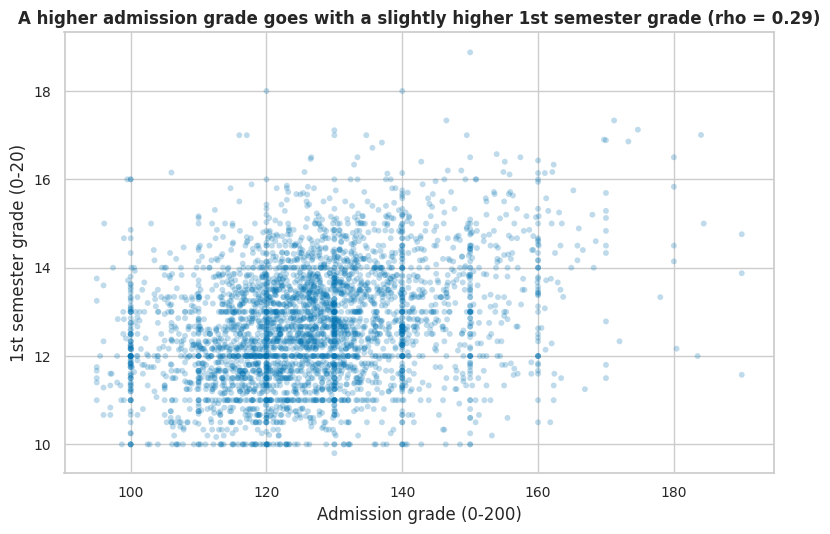

In [ ]:
rho = spearman_test(data, "Admission_Grade", "Grade_1st")
rho_rate = spearman_test(data, "Admission_Grade", "Approval_Rate_1st")
print(data.groupby("Admission_Grade_Band", observed=True)["Grade_1st"].agg(["count", "median"]).round(2))

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=data, x="Admission_Grade", y="Grade_1st", color=BAR_COLOR, alpha=0.25, s=18,
                edgecolor="none", ax=ax)
ax.set_xlabel("Admission grade (0-200)")
ax.set_ylabel("1st semester grade (0-20)")
ax.set_title(f"A higher admission grade goes with a slightly higher 1st semester grade (rho = {rho:.2f})")
ax.title.set_fontsize(12)
plt.tight_layout()
plt.savefig("figures/blockD_admission_vs_grade.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft conclusion (check the numbers after running):** There is a weak positive association between the admission grade and the 1st semester grade (Spearman rho = 0.29, p < 0.001, n = 3706): the median grade goes from 12.1 in the lowest quartile of the admission grade to 13.3 in the highest. The admission grade is even less related to the share of units passed (rho = 0.17). The admission grade is therefore a weak predictor of university performance, and the points in the scatter are widely dispersed.

# Block D: summary

| No. | Question | Result | Effect size |
|---|---|---|---|
| D1 | Approved units by outcome | dropouts pass 41% (1st sem.) and 31% (2nd sem.) of their units, graduates 93% | large (epsilon squared 0.46 and 0.55) |
| D2 | Grades by outcome | graduates slightly higher (13.0 vs 12.0), only for students with a grade | medium (0.13 and 0.14) |
| D3 | Spotting dropouts after the 1st semester | 92% dropout among those who passed no unit, 9% among those who passed all; but only about half of dropouts show a weak 1st semester | strong (V = 0.61) |
| D4 | Recovery in the 2nd semester | grades do not change; only 10% of the struggling students recover | negligible for grades (0.005); strong for the 1st semester vs outcome (V = 0.59) |
| D5 | Admission grade and 1st semester grade | weak positive relationship | weak (rho = 0.29) |

**Take to the slides (1-2 charts):** the grouped bar chart of D1 (the gap between dropouts and graduates) and the dropout rate by approval band of D3 (the 1st semester already shows who is at risk). Everything else goes in the appendix.

**Take to Phase 4 (Random Forest):** the 1st semester approval rate is a very strong signal, but half of the dropouts do not show it: the three scenarios (at enrollment, after the 1st semester, after the 2nd semester) will show how much the prediction improves with each semester.

**Limits to say in the presentation:** performance is partly a consequence of dropout; grades exist only for students who passed at least one unit; 180 students enrolled in 0 units per semester are excluded from the approval rate; the data come from a single Portuguese institution; associations are not causal effects.